<a href="https://colab.research.google.com/github/juvowen/AlgoTrading/blob/main/Student's_t_Distribution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Student's t-Distribution

### What it is
The Student's t-distribution is a bell-shaped, symmetric distribution like the normal, but with **fatter tails**: it assigns more probability to extreme outcomes. One parameter, the **degrees of freedom** $\nu$, controls how heavy the tails are. Low $\nu$ means fat tails, and as $\nu \to \infty$ it becomes the normal distribution.

### The math behind it
Probability density function:

$$
f(x) = \frac{\Gamma\left(\frac{\nu+1}{2}\right)}{\sqrt{\nu\pi}\,\Gamma\left(\frac{\nu}{2}\right)} \left(1 + \frac{x^2}{\nu}\right)^{-\frac{\nu+1}{2}}
$$

- $\nu$ = degrees of freedom (tail thickness)
- $\Gamma$ = gamma function

Key properties:
- Mean $= 0$ (for $\nu > 1$)
- Variance $= \frac{\nu}{\nu - 2}$ (for $\nu > 2$; infinite for $\nu \le 2$)
- Excess kurtosis $= \frac{6}{\nu - 4}$ (for $\nu > 4$), always fatter-tailed than the normal
- The tails decay like a power law, $\sim |x|^{-(\nu+1)}$, instead of exponentially like the normal, $\sim e^{-x^2/2}$

For returns, add location $\mu$ and scale $\sigma$: $\; r = \mu + \sigma \, T_\nu$

### How it's used
- **Fitting returns:** estimate $\nu, \mu, \sigma$ from historical returns (`scipy.stats.t.fit`). Daily equity returns typically give $\nu \approx 3\text{–}6$.
- **Risk models:** VaR and Expected Shortfall computed from t-quantiles instead of normal quantiles.
- **GARCH volatility models:** used as the distribution of the shocks/residuals (`arch_model(..., dist='t')`).
- **Simulation / Monte Carlo:** generating realistic price paths with occasional large jumps.

### Why it's used
Real market returns are **not normal**. They have fat tails and sharp peaks. Under a normal model, a 5-sigma daily move should occur roughly once every several thousand years, yet markets produce them every few years. The t-distribution:
- captures crashes and spikes far more realistically,
- prevents risk (VaR, stop distances, position sizes) from being underestimated,
- stays simple: one extra parameter on top of the normal, with finite variance when $\nu > 2$, so standard tools like volatility and Sharpe ratios still work.

In [15]:
#parameters

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

gld = yf.download("GC=F",period="10y",interval="1d")
gld["Returns"] = gld["Close"].pct_change() * 100
returns = gld["Returns"].dropna()


/tmp/ipykernel_978/401669248.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  gld = yf.download("GC=F",period="10y",interval="1d")
[*********************100%***********************]  1 of 1 completed


Mean daily return: 0.0522%
Daily std dev:     1.0750%


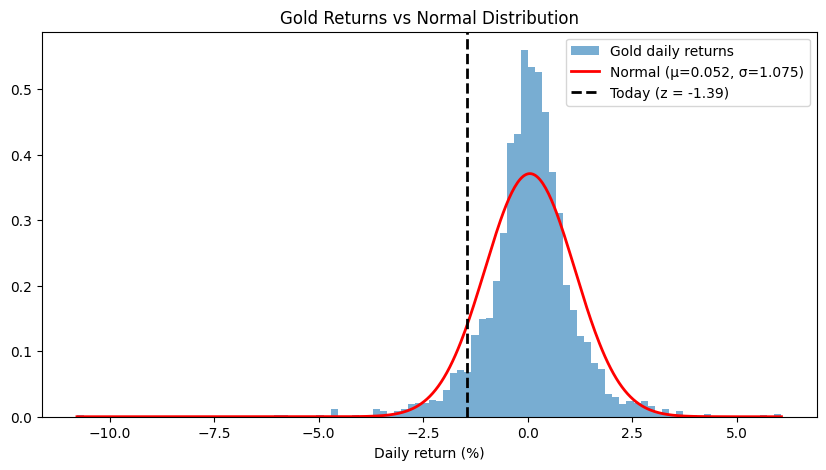

Date:            2026-11-10
Today's return:  -1.444%
Z-score:         -1.39
Normal model:    a move this size happens ~16.41% of days (about 1 in 6 days)


In [18]:
#Normal Distrubution

# 2. Daily returns in %
mu, sigma = stats.norm.fit(returns)
print(f"Mean daily return: {mu:.4f}%")
print(f"Daily std dev:     {sigma:.4f}%")

# 4. Plot histogram vs normal curve
x = np.linspace(returns.min(), returns.max(), 500)
plt.figure(figsize=(10, 5))
plt.hist(returns, bins=100, density=True, alpha=0.6, label="Gold daily returns")
plt.plot(x, stats.norm.pdf(x, mu, sigma), "r-", lw=2, label=f"Normal (μ={mu:.3f}, σ={sigma:.3f})")
plt.axvline(current_return, color="black", ls="--", lw=2, label=f"Today (z = {z:.2f})")
plt.xlabel("Daily return (%)")
plt.title("Gold Returns vs Normal Distribution")
plt.legend()
plt.show()

# Current (latest) daily return
current_return = returns.iloc[-1]
current_date = returns.index[-1].date()

# Z-score: how many standard deviations from the mean
z = (current_return - mu) / sigma

# How often a move this big or bigger should happen under the normal model
p_normal = 2 * stats.norm.sf(abs(z))   # two-sided

print(f"Date:            {current_date}")
print(f"Today's return:  {current_return:.3f}%")
print(f"Z-score:         {z:.2f}")
print(f"Normal model:    a move this size happens ~{p_normal:.2%} of days "
      f"(about 1 in {1/p_normal:,.0f} days)")


Degrees of freedom (ν): 3.12
Location (μ):           0.0741%
Scale (σ):              0.6943%


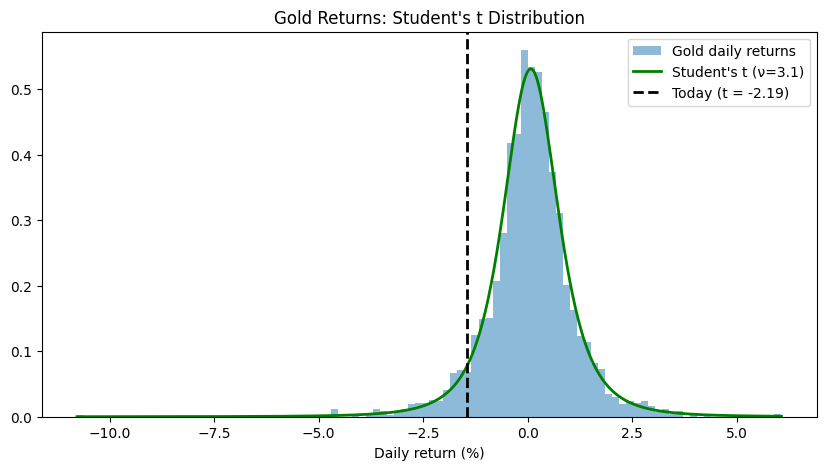

Date:           2026-11-10
Today's return: -1.444%
t-score:        -2.19
Probability:    ~1 in 9 days


In [20]:
#Student T distro
returns = gld["Returns"].squeeze().dropna()

df_t, loc_t, scale_t = stats.t.fit(returns)

print(f"Degrees of freedom (ν): {df_t:.2f}")
print(f"Location (μ):           {loc_t:.4f}%")
print(f"Scale (σ):              {scale_t:.4f}%")

# Current t-score (calculated BEFORE plotting)
current_Treturn = returns.iloc[-1]
t_score = (current_Treturn - loc_t) / scale_t
p_t = 2 * stats.t.sf(abs(t_score), df_t)

# Plot
x = np.linspace(returns.min(), returns.max(), 1000)

plt.figure(figsize=(10, 5))
plt.hist(returns, bins=100, density=True, alpha=0.5, label="Gold daily returns")
plt.plot(x, stats.t.pdf(x, df_t, loc_t, scale_t), "g-", lw=2, label=f"Student's t (ν={df_t:.1f})")
plt.axvline(current_Treturn, color="black", ls="--", lw=2, label=f"Today (t = {t_score:.2f})")
plt.xlabel("Daily return (%)")
plt.title("Gold Returns: Student's t Distribution")
plt.legend()
plt.show()

print(f"Date:           {returns.index[-1].date()}")
print(f"Today's return: {current_Treturn:.3f}%")
print(f"t-score:        {t_score:.2f}")
print(f"Probability:    ~1 in {1/p_t:,.0f} days")

## How to Use the Student's t-Distribution (A Trader's Guide)

### The big idea
Markets don't move in a neat, predictable bell curve. Most days are quiet, but every so often there's a **huge move**: a crash, a spike, a news shock. The regular (normal) distribution says those big moves almost never happen. **The Student's t-distribution admits they do**, so it gives you a more honest picture of risk.

### Reading the chart
- **Blue bars:** how often each daily return actually happened in the past.
- **Green curve:** the Student's t model fitted to that history.
- **Dashed line:** today's move. The further it sits from the center, the more unusual today is.

### The three numbers the model gives you
| Number | What it means | In plain English |
|---|---|---|
| **Location (μ)** | The center of the distribution | The average daily move (usually close to 0) |
| **Scale (σ)** | The spread of typical days | How much the asset normally moves on a quiet day |
| **Degrees of freedom (ν)** | How heavy the tails are | How prone the asset is to big shocks |

**How to read ν:**
- **ν below 5:** very fat tails. Big moves happen often; be careful with size and stops.
- **ν between 5 and 30:** moderate fat tails.
- **ν above 30:** behaves almost like a normal distribution.

### The t-score
The t-score works like a z-score: it tells you **how far today's move is from normal**.
- Close to **0**: an ordinary day.
- Far from 0 (positive or negative): an unusual day.

**Important:** don't judge the t-score by the usual "above 2 is rare" rule. When tails are fat, a score of 2 or 3 can be fairly common. **Always look at the probability line instead** (e.g. "~1 in 9 days" vs "~1 in 200 days"). That's what tells you how rare the move really is.

### How traders use it
1. **Spotting unusual moves:** pick a rarity level (for example, "a move I'd only expect 1 in 100 days"). If today's move is rarer than that, look closer: check news, volume and the trend.
2. **Sizing positions:** use the model to estimate a realistic bad day. If your account can't survive that loss, your position is too big.
3. **Placing stop-losses:** put stops outside the asset's normal daily noise so you're not knocked out by ordinary randomness.
4. **Watching risk change over time:** if ν starts dropping, the market is getting jumpier. Consider trading smaller.

### Things to keep in mind
- The model is built on **past data**. It describes how the asset has behaved, not a guarantee of what comes next.
- An unusual move is a **reason to investigate**, not a buy or sell signal on its own.
- Use enough history (several years of daily data) for the fit to be reliable.
- If you run it during market hours, today's return is based on a live price and will change by the close.